# Group Project Cryosphere

Earth Observation group project about a glacier in the Himalaya in Nepal. We try to measure glacier area, surface temperature variation, and wet/total snow area using satellite data from Google Earth Engine. We investigate these aspects on the time series of 2015 - 2026.

## Initializing

In [9]:
import ee
import os
import geemap
import numpy as np
import pandas as pd
import plotting as pl
import glacier_area as ga
import gst_line as gl
import sar_snow as ss
import io_param_functions as ipf

In [10]:
# run once at beginning, supply token
ee.Authenticate()
GEE_PROJECT = "my-hello-world-508910"  # replace with your own project id
ee.Initialize(project=GEE_PROJECT)

In [11]:
ROI = [[81.768322, 30.198924], [81.785316, 30.200185], [81.782656, 30.20241], [81.780596, 30.2079], [81.780252, 30.215613], [81.780424, 30.223327], [81.778965, 30.228741], [81.776733, 30.231707], [81.774759, 30.231781], [81.771927, 30.225403], [81.77021, 30.216503], [81.770382, 30.211237], [81.770296, 30.206416], [81.766691, 30.202707], [81.765575, 30.199962], [81.768322, 30.198924]]
AOI = ee.Geometry.Polygon(ROI)

In [12]:
START = "2014-09-01"
END = "2026-12-31"
YEARS = list(range(2015, 2027))

DEBUG = True
SAVE_PATH = "results"

In [13]:
glims = ee.FeatureCollection("GLIMS/current").filterBounds(AOI)  # keep: all years, needed for the area history
glims_areas = ga.glims_area_by_year(glims, AOI, debug=True, min_year_inclusive=2000)
glacier_glims_geom = ipf.get_latest_glims(AOI, debug=True)
glacier_glims_geom

1967: 1.87; 1967: 0.02; 1967: 0.03; 2010: 1.60; 2010: 0.02; 2001: 1.87; 1450: 2.33; 
Total: 2001: 1.87; 2010: 1.61;
GLIMS src_date: 2010-11-15T00:00:00


ee.Geometry({
  "functionInvocationValue": {
    "functionName": "Geometry.intersection",
    "arguments": {
      "left": {
        "functionInvocationValue": {
          "functionName": "Collection.geometry",
          "arguments": {
            "collection": {
              "functionInvocationValue": {
                "functionName": "Collection.filter",
                "arguments": {
                  "collection": {
                    "functionInvocationValue": {
                      "functionName": "Collection.filter",
                      "arguments": {
                        "collection": {
                          "functionInvocationValue": {
                            "functionName": "Collection.loadTable",
                            "arguments": {
                              "tableId": {
                                "constantValue": "GLIMS/current"
                              }
                            }
                          }
                        },
                        "filter": {
                          "functionInvocationValue": {
                            "functionName": "Filter.intersects",
                            "arguments": {
                              "leftField": {
                                "constantValue": ".all"
                              },
                              "rightValue": {
                                "functionInvocationValue": {
                                  "functionName": "Feature",
                                  "arguments": {
                                    "geometry": {
                                      "functionInvocationValue": {
                                        "functionName": "GeometryConstructors.Polygon",
                                        "arguments": {
                                          "coordinates": {
                                            "constantValue": [
                                              [
                                                [
                                                  81.768322,
                                                  30.198924
                                                ],
                                                [
                                                  81.785316,
                                                  30.200185
                                                ],
                                                [
                                                  81.782656,
                                                  30.20241
                                                ],
                                                [
                                                  81.780596,
                                                  30.2079
                                                ],
                                                [
                                                  81.780252,
                                                  30.215613
                                                ],
                                                [
                                                  81.780424,
                                                  30.223327
                                                ],
                                                [
                                                  81.778965,
                                                  30.228741
                                                ],
                                                [
                                                  81.776733,
                                                  30.231707
                                                ],
                                                [
                                                  81.774759,
                                                  30.231781
                                                ],
                        

## Image Collections Analysis

Get a sense of how many Images we are working with, from what date they are and how much they are covered by clouds.

In [14]:
s2_toa = ee.ImageCollection("COPERNICUS/S2_HARMONIZED").filterBounds(AOI).sort("system:time_start").set("collection_name", "Sentinel 2 Top of Atmosphere")
s2_boa = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(AOI).sort("system:time_start").set("collection_name", "Sentinel 2 Bottom of Atmosphere")

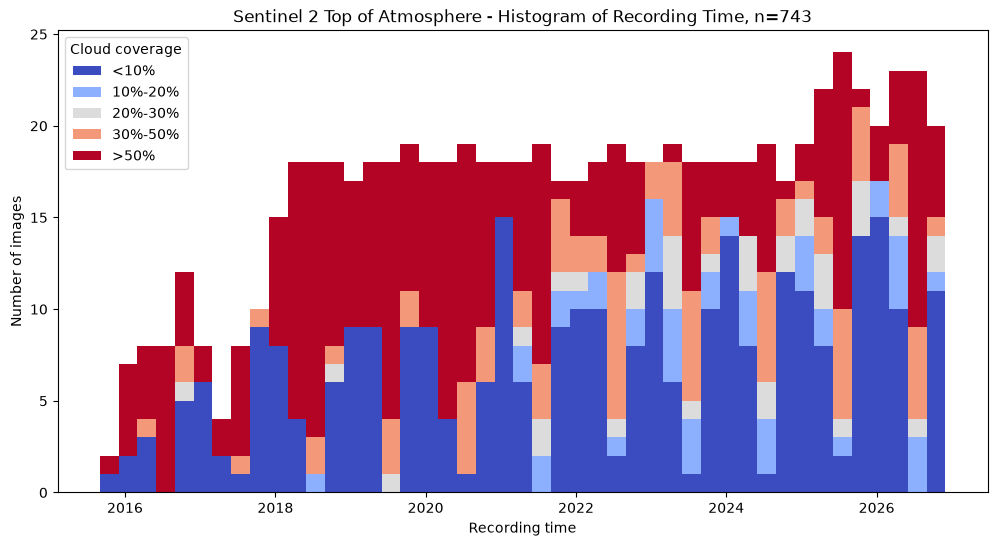

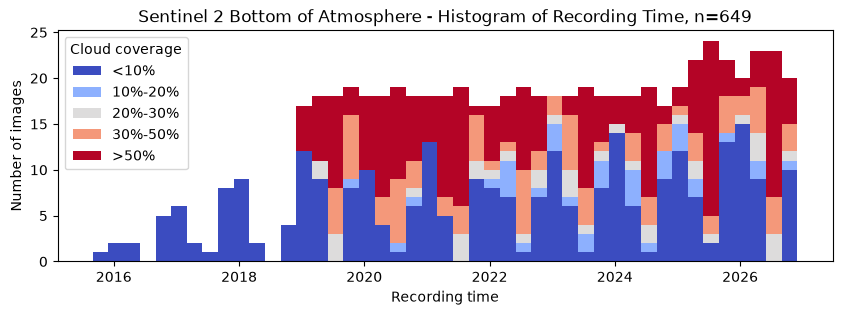

In [15]:
fig_s2_toa_obsv = pl.plot_histogram_image_collection(s2_toa, "2015-09-01", "2027-01-01")
fig_s2_boa_obsv = pl.plot_histogram_image_collection(s2_boa, "2015-09-01", "2027-01-01", fig_size=(10,3))
ipf.save_any_tables_and_figures({"S2_BOA_number_of_observations": fig_s2_boa_obsv}, save_path="results/")

## Snow/ice area

Sentinel 2 median -> NDSI -> greater than 0.4

In [16]:
masks = ga.download_snow_masks(AOI, YEARS, months=(7, 9), debug=False)
# map_area = pl.map_glacier_area(masks, AOI, glacier_glims_geom)
# map_area

In [17]:
season_df = ga.area_by_season(AOI, YEARS, debug=False)  # glacier_mask=glacier_mask restricts to GLIMS
ipf.save_any_tables_and_figures({"area_by_season": season_df}, save_path=os.path.join(SAVE_PATH, "glacier_area"))

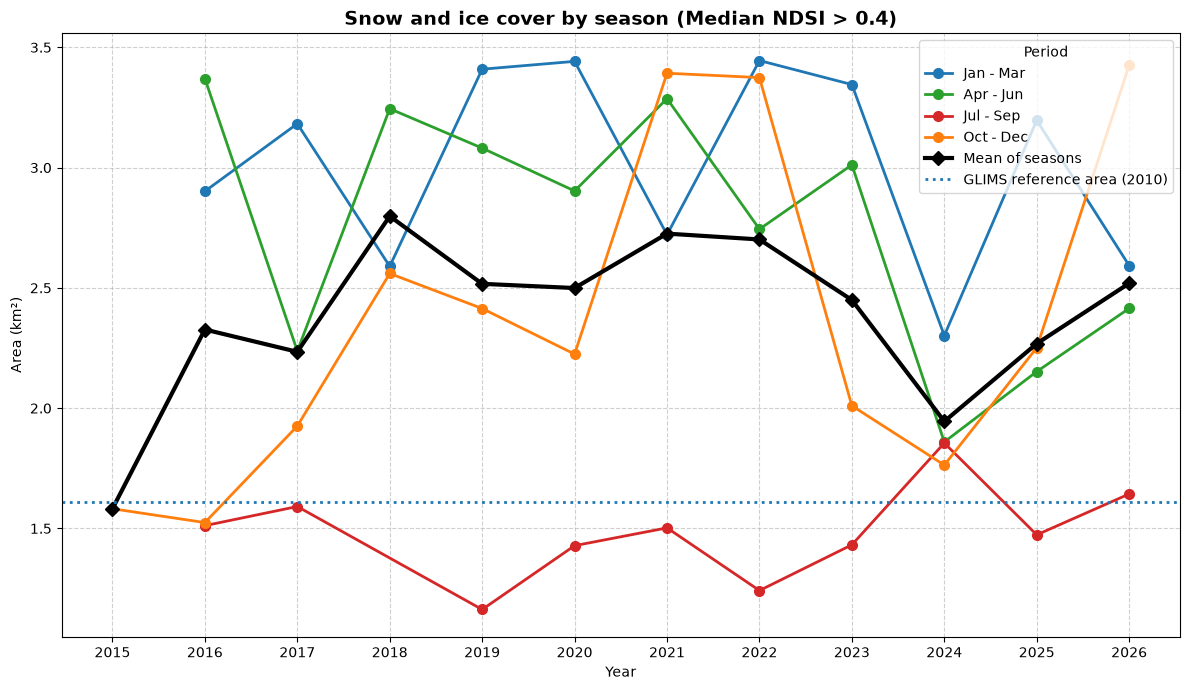

In [18]:
fig_seasons = pl.plot_glacier_area_seasons(season_df, glims_areas, min_year_inclusive=2015)

In [ ]:
for area_year in YEARS:
    month_df = ga.area_by_month(AOI, area_year, debug=True)
    fig_months = pl.plot_glacier_area_months(month_df, area_year)
    ipf.save_any_tables_and_figures(
        {f"area_months_{area_year}": month_df,
         f"area_months_fig_{area_year}": fig_months},
        save_path="results/glacier_area/per_month",
        debug=True
    )

2015-01-01 .. 2015-01-31: 0 scenes
2015-01: None
2015-02-01 .. 2015-02-28: 0 scenes
2015-02: None
2015-03-01 .. 2015-03-31: 0 scenes
2015-03: None
2015-04-01 .. 2015-04-30: 0 scenes
2015-04: None
2015-05-01 .. 2015-05-31: 0 scenes
2015-05: None
2015-06-01 .. 2015-06-30: 0 scenes
2015-06: None
2015-07-01 .. 2015-07-31: 0 scenes
2015-07: None
2015-08-01 .. 2015-08-31: 0 scenes
2015-08: None
2015-09-01 .. 2015-09-30: 0 scenes
2015-09: None
2015-10-01 .. 2015-10-31: 1 scenes
2015-10: 1.5818831731857002
2015-11-01 .. 2015-11-30: 0 scenes
2015-11: None
2015-12-01 .. 2015-12-31: 0 scenes
2015-12: None

Saving: area_months_2015.csv area_months_fig_2015.png 
Done Saving.
2016-01-01 .. 2016-01-31: 1 scenes
2016-01: 2.673316790725169
2016-02-01 .. 2016-02-29: 1 scenes
2016-02: 3.3631582793891432
2016-03-01 .. 2016-03-31: 1 scenes
2016-03: 2.695670254531799
2016-04-01 .. 2016-04-30: 1 scenes
2016-04: 3.3703996947548034
2016-05-01 .. 2016-05-31: 0 scenes
2016-05: None
2016-06-01 .. 2016-06-30: 0 sc

In [ ]:
ipf.save_any_tables_and_figures(
    {"area_seasons": season_df,
     "area_seasons_fig": fig_seasons},
    save_path="results/glacier_area",
    debug=DEBUG
)

## Surface temperature variation (gst_line)

In [ ]:
Map = geemap.Map(basemap="HYBRID")
Map.centerObject(AOI, 14)
Map.addLayer(ee.Image().paint(AOI, 1, 2), {"palette": ["red"]}, "AOI")
Map.addLayer(ee.Image().paint(glacier_glims_geom, 1, 2), {"palette": ["blue"]}, "Glims outline")
Map

In [ ]:
aoi_coords = [
    [81.756821, 30.184416],
    [81.791840, 30.184416],
    [81.791840, 30.255022],
    [81.756821, 30.255022],
    [81.756821, 30.184416]
]
BBOX = ee.Geometry.Polygon(aoi_coords)

In [ ]:
lst = gl.download_lst(BBOX, START, END, max_cloud=60, debug=DEBUG)
stack = gl.season_stack(lst, BBOX)
n_season = gl.season_count(lst, debug=DEBUG)

In [ ]:
# to use a hand-drawn line: draw it on a Map = geemap.Map, then pass user_roi=Map.user_roi
line = gl.get_centerline([[81.774, 30.225], [81.776, 30.220], [81.775, 30.195]][::-1], user_roi=None, debug=DEBUG)
map_lst = pl.map_gst_line_map(stack, BBOX, glacier_glims_geom, line)
map_lst

In [ ]:
profile_df = gl.temp_profile(stack, line, step_m=150, debug=DEBUG)
fig_profile = pl.plot_gst_line_profile(profile_df, n_season, glacier_beginning_m=600, glacier_end_m=2600)

In [ ]:
arrays = gl.season_arrays(stack, BBOX)
fig_gl_spatial = pl.plot_gst_line_seasons(arrays, gl.roi_extent(BBOX), n_season, AOI, glims=glacier_glims_geom)

In [ ]:
scene_df = gl.scene_temp_table(lst, ipf.study_region(AOI, glacier_glims_geom), debug=DEBUG)
fit_df, curve_df, stats = gl.fit_temp_trend(scene_df)
fig_ts = pl.plot_gst_line_timeseries(fit_df, curve_df, stats)

In [ ]:
ipf.save_any_tables_and_figures(
    {"lst_profile": profile_df,
     "lst_scenes": scene_df,
     "lst_profile_fig": fig_profile,
     "lst_spatial_fig": fig_spatial,
     "lst_timeseries_fig": fig_ts},
    save_path="results/gst_line",
    debug=DEBUG
)

## Wet snow area

In [ ]:
glacier_mask, mask_status = ipf.get_glacier_mask(AOI, debug=True)

In [ ]:
REF = (12, 1, 2)
WET = (3, 4, 5)

In [ ]:
SY = 2024
ORBIT = "ASCENDING"
MONTHS = (12, *range(1, 7))

DAY_TICKS_ALL = ([32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335, 0],
                 ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])

day_ticks = ([DAY_TICKS_ALL[0][m - 1] for m in MONTHS],
             [DAY_TICKS_ALL[1][m - 1] for m in MONTHS])
print(day_ticks)

In [ ]:
df, bdf = ss.all_stats(AOI, "2015-12-01", "2025-06-01", glacier_mask=glacier_mask, ref_months=REF, wet_months=WET)

In [ ]:
monthly_table = ss.monthly_mean_table(df)

fig_snow_series = ss.plot_sar_snow_series(df)
fig_snow_season = ss.plot_sar_snow_season(df, day_ticks=day_ticks)

In [ ]:
ipf.save_any_tables_and_figures(
    {"snow_scenes": df,
     "snow_elev_bands": bdf,
     "monthly_table": monthly_table,
     "sar_snow_series": fig_snow_series,
     "sar_snow_season": fig_snow_season},
    save_path="results/sar_snow/",
)

In [ ]:
fig_snow_elev = ss.plot_sar_snow_elev(bdf, SY, ORBIT) # wet fraction by elevation band and date
fig_snow_diff_history = ss.show_sar_snow_diff_history(AOI, SY, ORBIT, months=(12, *range(1, 12))) # backscatter-change histogram per month, threshold marked
fig_ss_snow_months = ss.show_sar_snow_month_images(AOI, SY, ORBIT, months=(3, 4, 5), glims=glims, ref_months=REF, wet_months=WET)

In [ ]:
map_snow_maps = ss.show_sar_snow_maps(AOI, SY, ORBIT, months=(12, *range(1, 12)), glacier_mask=glacier_mask) # monthly wet frequency and melt-onset day
map_snow_maps

In [ ]:
ipf.save_any_tables_and_figures(
    {f"sar_snow_elev_{SY}_{ORBIT}": fig_snow_elev,
     f"sar_snow_diff_history_{SY}_{ORBIT}": fig_snow_diff_history,
     f"sar_snow_maps_{SY}_{ORBIT}": map_snow_maps,
     f"sar_snow_months_{SY}_{ORBIT}": fig_ss_snow_months,},
    save_path="results/sar_snow/",
)